**First time here?** Start with the quick start, [`quickstart_sdk.ipynb`](quickstart_sdk.ipynb) (one 16 × 16 image and its result from a shipped recipe, then another sensor), and the [user manual](../docs/User_manual.md) with its [glossary](../docs/User_glossary.md). This notebook covers the SDK's public surfaces one by one (the library reads, compose with the run id and provenance, the run-spec loader and the published engine-block schema, validation with a deliberate refusal, submission, artifacts by role, a byte-identical repeat) and the layered comparison of a DIRSIG demo against its pass-through run.

# Stage 05 — the SDK end to end: an AUROR-style job through the `Workspace`

Stages 01 to 04 drove DIRSIG through the run-spec driver and `LocalRegistry`. This notebook drives the same AUROR-style job only through the SDK's public surfaces: the `Workspace` (library reads, compose, validate, submit, status and verdict, artifacts), the run-spec loader (`manifold.core.run_spec.load_run_spec`) and the engine-block schema the engine publishes (`Workspace.list_engines`). The steps:

1. **Recipe.** A `compose/1` recipe document built in a cell from the library's AUROR_ref recipe: the same sensor (`auror-nir.yaml`), scenario (`tahoe_static_pose`) and engine profile, a 16 × 16 window, and one CPU thread (a copy of the engine profile with `resources.cpu_threads: 1`, so that a repeat is byte-identical).
2. **Compose.** The run spec it resolves to, its run id, and where each member came from; the run spec written to a file and read back with the run-spec loader; the engine block checked against the published `dirsig-engine/1` schema.
3. **Validate.** The engine-free checks, the DIRSIG dry run, and one deliberate failure: the round 22 uniform `BasicAtmosphere` (`engine.atmosphere.uniform`) stated with no weather values, refused with the reason.
4. **Submit.** One 16 × 16 render through the `Workspace`; the artifacts by role; the state and the verdict.
5. **Compare.** A second run of the same recipe in a second work root: the same run id, and the same product bytes. Then, if the DIRSIG installation holds the MaterialMap1 demo archive, the layered-comparison metric of round 22 (`scripts/compare_layered.py`): that demo in the layered form (`engine.atmosphere.uniform`, `engine.platform.as_authored`) against the demo run as authored (pass-through) at the same seed, both at 16 × 16.

What is demonstrated: the SDK calls a client makes, end to end, on this machine (`Workspace.local`), and that their results are reproducible. What is not: a remote backend (`Workspace.remote` is phase 3), a sweep (stage 03), radiometric validity of the AUROR scene (the vehicle renders black in this band; see stage 01's fidelity block), and anything at native size (every render here is 16 × 16). The demo's values in the layered comparison are licensed: they are derived at run time from the local DIRSIG installation into a folder outside the repository, exactly as `scripts/compare_layered.py` derives them, and this notebook prints none of them.

---
# Setup

From a fresh clone, run `python scripts/bootstrap.py install` once (DIRSIG linked as `external/dirsig`). This cell puts DIRSIG's `bin/` on `PATH` when an installation is there; unlike stages 01 to 04 it does not stop without one, because the engine-free steps run anyway: the SDK says whether the DIRSIG engine is available (`Workspace.list_engines`), and every cell that needs it prints why it skips. Everything the notebook writes goes under `outputs/stage_05_sdk_auror_demo/` (the layered comparison's derived demo files go under the state directory instead, outside the repository); `STAGE05_WORK` and `STAGE05_LAYERED_WORK` move them (the suite's test does).

In [1]:
import os
import shutil
import sys
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXTERNAL = PROJECT / "external"                       # populated by scripts/bootstrap.py install
if not os.environ.get("DIRSIG_HOME") and (EXTERNAL / "dirsig" / "bin" / "dirsig5").is_file():
    os.environ["DIRSIG_HOME"] = str((EXTERNAL / "dirsig").resolve())
if os.environ.get("DIRSIG_HOME"):
    os.environ["PATH"] = f"{Path(os.environ['DIRSIG_HOME']) / 'bin'}{os.pathsep}" + os.environ.get("PATH", "")
try:
    import manifold.sim
except ImportError:                                      # not installed: the two source trees of the manifold namespace
    sys.path[:0] = [str(PROJECT / "packages" / d / "src") for d in ("core", "sim")]
    import manifold.sim

from manifold.sim import Workspace
from manifold.sim.workspace import default_work_root

LIBRARY = PROJECT / "manifold_run_specs"              # the layer library, read only
WORK = Path(os.environ.get("STAGE05_WORK") or PROJECT / "outputs" / "stage_05_sdk_auror_demo")
LAYERED_WORK = Path(os.environ.get("STAGE05_LAYERED_WORK") or default_work_root().parent / "stage05-layered-comparison")
for d in (WORK, LAYERED_WORK):
    if d.exists():
        shutil.rmtree(d)                              # our own directories
    d.mkdir(parents=True)
print("manifold.sim :", manifold.sim.__version__)
print("DIRSIG_HOME  :", os.environ.get("DIRSIG_HOME", "(not set)"))

manifold.sim : 0.0.1
DIRSIG_HOME  : /home/kevin-kearney/DIRSIG/dirsig-2026.38.0.a020954-Linux-x86_64


---
# Step 1 — The recipe

A recipe names its layers by library name; the `Workspace` reads them from its library. The notebook's library is a copy of the repository's three layer folders under `WORK` (the repository's stay untouched), plus one new engine profile, `stage05_auror`: the AUROR engine profile `tahoe_static_pose` as authored, with `resources.cpu_threads: 1` added. One thread is what makes two DIRSIG renders bit-identical; a seed alone does not (CONOPS and Guide §9, "Precision and seeds"). The recipe itself starts from the library's `auror_ref` recipe as `get_recipe` returns it and changes three members: its name, its engine profile, and a 16 × 16 window.

In [2]:
import copy
import yaml

library = WORK / "library"
for d in ("recipes", "scenarios", "engine_profiles"):
    shutil.copytree(LIBRARY / d, library / d)
profile = yaml.safe_load((LIBRARY / "engine_profiles" / "tahoe_static_pose.yaml").read_text())
profile["resources"] = {"cpu_threads": 1}
(library / "engine_profiles" / "stage05_auror.yaml").write_text(yaml.safe_dump(profile, sort_keys=False))

SENSORS = PROJECT / "manifold_sensors"              # the sensor library, read only
ws = Workspace.local(library=library, work=WORK / "work_a", sensor_library=SENSORS)
print("recipes :", [i.name for i in ws.list_recipes().items])
print("sensors :", [i.name for i in ws.list_sensors().items])

recipe = copy.deepcopy(ws.get_recipe("auror_ref").document)
recipe["meta"]["name"] = "stage05-auror-sdk-demo"
recipe["engine_profile"] = "stage05_auror"
for member in recipe["settings"]:
    member["roi"] = {"Width": 16, "Height": 16, "OffsetX": None, "OffsetY": None}
print()
print(yaml.safe_dump(recipe, sort_keys=False, width=120))

recipes : ['auror_ref', 'demo_brdf1_passthrough', 'demo_pointcollectors2_passthrough', 'leo_pass_tahoe', 'pointcollectors2_demo', 'sensor_sweep_tahoe', 'synthetic_vis']
sensors : ['auror-nir.yaml', 'deepscan_850_306_nir_1280.yaml', 'synthetic_600_200_vis_1920.yaml']

compose: compose/1
meta:
  name: stage05-auror-sdk-demo
  tags:
  - auror
  - nir
  - static-pose
  - hypersonic-target
  description: 'Received static-pose detection scene: a NIR staring sensor at a fixed LEO-altitude position over the Tahoe
    scene, with an embedded hypersonic target track.

    '
sensor: auror-nir.yaml
scenario: tahoe_static_pose
engine_profile: stage05_auror
engine_overrides:
  platform.channel_response: native
settings:
- entry_id: auror-nir
  exposure_time:
    value: 0.005
    provenance: specified
  frame_rate:
    value: 1000
    provenance: specified
  gain:
    value: 1
    provenance: specified
  black_level:
    value: 0
    provenance: specified
  roi:
    Width: 16
    Height: 16
    Offse

---
# Step 2 — Compose

`Workspace.compose` resolves the recipe into `run-spec/1` documents without running anything (one here; a sweep recipe gives one per sensor). Each run comes with its run id, the sha256 of the run spec's canonical JSON with the sensor's block in place, and the provenance of each member: the layer file and its sha256.

In [3]:
composed = ws.compose(recipe)
run = composed.runs[0]
spec = run.run_spec
print("runs   :", len(composed.runs), "| sweep:", composed.is_sweep)
print("run id :", run.run_id)
print("name   :", run.name, "| sensor:", run.sensor)
print()
for member, src in run.provenance.items():
    print(f"{member:24s} {src.layer:44s} {(src.content_hash or '')[:19]}")
print()
print(yaml.safe_dump(spec, sort_keys=False, width=120))

runs   : 1 | sweep: False
run id : b0f3c6cfaff57edea41ef9ae0ee9496ce03515c8e6f6dd3246811d98ab349670
name   : stage05-auror-sdk-demo | sensor: auror-nir.yaml

spec_version             rules compose/1                              
descriptor.meta          (recipe document)                            sha256:927d2ed0366a
descriptor.origin        engine_profiles/stage05_auror.yaml           sha256:ef483d52f73e
descriptor.collection    scenarios/tahoe_static_pose.yaml             sha256:e6172b88f555
descriptor.sensor        manifold_sensors/auror-nir.yaml              sha256:0f8c20403e1d
descriptor.settings      (recipe document)                            sha256:927d2ed0366a
descriptor.fidelity      (recipe document)                            sha256:927d2ed0366a
descriptor.extras        engine_profiles/stage05_auror.yaml           sha256:ef483d52f73e
engine                   engine_profiles/stage05_auror.yaml           sha256:ef483d52f73e
engine.platform.channel_response (recipe document) 

The run spec can be stored as a file and read back with the run-spec loader; the loader returns plain dicts, and the run id of what it reads is the same. The engine block is checked against the schema the DIRSIG engine publishes: `list_engines` names each engine's contracts and the location of each engine-block schema, so a client in any language can apply the same check admission applies (the run-spec schema alone leaves the engine block open). `manifold.core.contract.engine_block_violations` is that check in Python.

In [4]:
from manifold.core.compose import dump
from manifold.core.contract import engine_block_violations
from manifold.core.run_spec import load_run_spec

spec_file = WORK / "stage05_auror.yaml"
spec_file.write_text(dump(spec, "stage05 recipe document"))
loaded = load_run_spec(spec_file)
print("loader round trip equal :", loaded == spec)
print("run id of the file      :", ws.compose(recipe).runs[0].run_id == ws.validate(spec_file).runs[0].run_id)

engines = {e.engine_id: e for e in ws.list_engines().items}
dirsig = engines["dirsig"]
print()
print("engine dirsig available :", dirsig.available, "|", dirsig.reason or "")
print("adapter version         :", dirsig.adapter_version)
print("modes / contracts       :", dirsig.modes, "/", dirsig.contracts)
for s in dirsig.schemas:
    print("engine-block schema     :", s.schema_id, "->", s.location)
print("engine-block violations :", engine_block_violations(loaded))
HAVE_DIRSIG = dirsig.available

loader round trip equal : True
run id of the file      : True



engine dirsig available : True | 
adapter version         : 0.0.1
modes / contracts       : ('layered', 'passthrough') / ('dirsig-engine/1',)
engine-block schema     : https://schemas.manifold.example/contracts/dirsig-engine-1.schema.json -> manifold_contracts/dirsig-engine-1.schema.json
engine-block violations : []


---
# Step 3 — Validate

`Workspace.validate` runs admission's checks without submitting: the run-spec and engine-block schemas, resolution of every reference against the libraries with the stamped content hashes verified, and the library-file check. With `engine_check="dry_run"` it adds a DIRSIG dry run (needs DIRSIG).

In [5]:
def show(result):
    for r in result.runs:
        print(f"valid={r.valid}  engine_checked={r.engine_checked}  run_id={(r.run_id or '-')[:16]}")
        for c in r.checks:
            print(f"  {c.check:14s} {'passed' if c.passed else 'FAILED'}")
            for e in c.errors:
                print(f"      {e.title} (status {e.status})")
                print(f"      {e.detail}")
                for entry in e.errors or ():
                    print(f"      run {entry.run}: field {entry.field}: {entry.detail}")

show(ws.validate(recipe))
print()
if HAVE_DIRSIG:
    show(ws.validate(recipe, engine_check="dry_run"))
else:
    print("SKIPPED: the DIRSIG dry run needs the DIRSIG engine:", dirsig.reason)

valid=True  engine_checked=False  run_id=b0f3c6cfaff57ede
  schema         passed
  resolution     passed
  content_hash   passed
  library_files  passed



Material [Dummy] ID has already been set to [N/A], can't override.


valid=True  engine_checked=True  run_id=b0f3c6cfaff57ede
  schema         passed
  resolution     passed
  content_hash   passed
  library_files  passed
  dry_run        passed


The deliberate failure. Round 22 added `engine.atmosphere.uniform` for DIRSIG's `BasicAtmosphere`: uniform radiative transfer, the installation's weather file and, optionally, a fixed Sun. Here the run spec states the radiative transfer but no weather values (and no library weather file, which a uniform atmosphere refuses anyway). The schema accepts it, on purpose: the refusal comes from the DIRSIG loader's rule, so that it carries DIRSIG's own reason and names the member rather than a bare "required property"; it is reported by the resolution check. The values stated are illustrative, not a demo's.

In [6]:
bad = copy.deepcopy(spec)
bad["engine"]["atmosphere"] = {"plugin": "basic", "uniform": {"radiative_transfer": {"hemisphere_irradiance": 1.0,
                                                                                    "sky_fraction": 0.2}}}
bad["engine"].pop("weather")
refused = ws.validate(bad)
show(refused)
assert not refused.runs[0].valid

valid=False  engine_checked=False  run_id=26ea0d789fbfbe42
  schema         passed
  resolution     FAILED
      The submission failed admission (status 422)
      Run stage05-auror-sdk-demo: a reference does not resolve: engine.atmosphere.uniform has no weather values: BasicAtmosphere reads its uniform weather from the .atm file and DIRSIG refuses a .atm without one ('Expected a <filename> in uniform weather'); state weather.install_file, a weather file of the DIRSIG installation (the demos use mls.wth)


---
# Step 4 — Submit

`submit_run` admits the recipe and returns at once with state `accepted`; `wait` (a helper built only from `get_run`) polls until a final state. The status carries the verdict, whether the outputs the engine's adapter expects are all there, and the artifact references; each reference has a role (what it is to a user of the run), a sha256, a media type and a `file://` URI. `save_artifact` writes one and checks its sha256.

In [7]:
import time
from collections import defaultdict

if HAVE_DIRSIG:
    t0 = time.monotonic()
    status = ws.submit_run(recipe)
    print("submitted :", status.state, status.run_id == run.run_id)
    final = ws.wait(status.run_id, timeout=600, poll=1.0)
    print(f"final     : {final.state}, verdict {final.verdict}, {time.monotonic() - t0:.0f} s")
    for e in final.errors:
        print("  error:", e.title, e.detail)
    by_role = defaultdict(list)
    for a in ws.list_artifacts(final.run_id).artifacts:
        by_role[a.role or "(no role)"].append(a)
    for role in sorted(by_role):
        print(f"\n{role}")
        for a in by_role[role]:
            print(f"  {a.name:40s} {a.sha256[:16]}  {a.media_type}" + ("" if a.frame is None else f"  frame {a.frame}"))
    again = ws.submit_run(recipe)
    print("\nsubmitted again: the same run, already", again.state, "| same id:", again.run_id == final.run_id)
else:
    final = None
    print("SKIPPED: submitting needs the DIRSIG engine:", dirsig.reason)

submitted : accepted True


final     : rendered, verdict complete, 6 s

config
  run_spec.json                            b0f3c6cfaff57ede  application/json

log
  run_info.json                            dda86e21365015b7  application/json
  log_info.json                            6ec092fe4b6b52ac  application/json

metadata
  AurorNIROutput.img.hdr                   6e2a09807500ec82  text/plain  frame 0
  truth1.img.hdr                           0e5b856cd540844d  text/plain  frame 0

product
  AurorNIROutput.img                       7e9732c6b6f37f9e  application/octet-stream  frame 0

truth
  truth1.img                               6cf460faa1588198  application/octet-stream  frame 0

submitted again: the same run, already rendered | same id: True


The product image, read from the bytes `get_artifact` returns. The SDK hands over bytes and a media type, not an array: reading an ENVI image is the client's business. This cell uses the repository's reader (`scripts/compare_outputs.py`'s `read_envi`, the one the layered comparison uses) on the saved files.

AurorNIROutput.img bands, lines, samples: (1, 16, 16) | per-band mean: ['1.44049e+15']


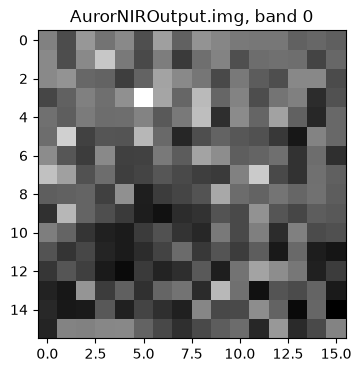

In [8]:
import matplotlib.pyplot as plt
sys.path.insert(0, str(PROJECT / "scripts"))
from compare_outputs import read_envi

def products(w, status, folder):
    # Each product image of a run saved under `folder` (the header beside it), {name: path}
    folder.mkdir(parents=True, exist_ok=True)
    refs = w.list_artifacts(status.run_id).artifacts
    names = {a.name for a in refs}
    out = {}
    for a in refs:
        if a.role == "product" and a.name.endswith(".img"):
            out[a.name] = w.save_artifact(status.run_id, a.name, folder)
            for h in (a.name + ".hdr", a.name[:-4] + ".hdr"):
                if h in names:
                    w.save_artifact(status.run_id, h, folder)
    return out

if final is not None and final.state == "rendered":
    images_a = products(ws, final, WORK / "files_a")
    name, path = next(iter(images_a.items()))
    img = read_envi(path)
    print(name, "bands, lines, samples:", img.shape, "| per-band mean:", [f"{m:.6g}" for m in img.reshape(img.shape[0], -1).mean(axis=1)])
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(img[0], cmap="gray")
    ax.set_title(f"{name}, band 0")
    plt.show()
else:
    images_a = {}
    print("SKIPPED: no rendered run to read")

---
# Step 5 — Compare

**A second run of the same recipe.** A second workspace with its own work root composes the same recipe to the same run id (the id depends only on the run spec) and renders it again. With one thread and the stated seed, the product bytes are the same.

In [9]:
import hashlib

ws_b = Workspace.local(library=library, work=WORK / "work_b", sensor_library=SENSORS)
print("same run id:", ws_b.compose(recipe).runs[0].run_id == run.run_id)
if final is not None and final.state == "rendered":
    final_b = ws_b.wait(ws_b.submit_run(recipe).run_id, timeout=600, poll=1.0)
    print("second run :", final_b.state, "verdict", final_b.verdict)
    images_b = products(ws_b, final_b, WORK / "files_b")
    for n in sorted(images_a):
        same = hashlib.sha256(images_a[n].read_bytes()).digest() == hashlib.sha256(images_b[n].read_bytes()).digest()
        print(f"  {n}: byte-identical {same}")
    sha_a = {a.name: a.sha256 for a in final.artifacts if a.role == "product"}
    sha_b = {a.name: a.sha256 for a in final_b.artifacts if a.role == "product"}
    print("every product reference's sha256 equal:", sha_a == sha_b)
else:
    print("SKIPPED: no rendered run to repeat")

same run id: True


second run : rendered verdict complete
  AurorNIROutput.img: byte-identical True
every product reference's sha256 equal: True


**Layered against pass-through.** Round 22's comparison (`scripts/compare_layered.py`, `docs/DIRSIG_layered_comparison.md`) renders a DIRSIG demo twice: in the layered form, whose recipe, scenario and engine profile are derived from the demo's own files (the atmosphere as `engine.atmosphere.uniform` read from the demo's `.atm`, the demo's `.platform` as `engine.platform.as_authored`, a static pose from its `.ppd`, the epoch and windows from its `.tasks`), and as authored, by the pass-through form. The metric: shape, per-band mean, maximum absolute difference, the fraction of pixels differing in any band, and the sha256 of each image. MaterialMap1 was byte-identical at native size and the same seed.

Here the same functions derive the layers, at 16 × 16: the demo's archive is extracted into a private library under `LAYERED_WORK` and its focal plane is cut to 16 × 16 there before anything is hashed (`xelementcount` and `yelementcount`; the window stays centred), so both forms render the same 16 × 16 camera. A layered recipe cannot ask for the window itself: with `as_authored` the descriptor's settings are checked but not applied. The demo's values stay in that folder; nothing below prints them.

In [10]:
from compare_layered import SIMULATION, compare, extract, passthrough_spec, write_layers
import lxml.etree as et

DEMO = "MaterialMap1"
zip_path = Path(os.environ.get("DIRSIG_HOME", "")) / "demos" / "zips" / f"{DEMO}.zip"
skip = (None if HAVE_DIRSIG and zip_path.is_file() else
        f"the DIRSIG engine is not available: {dirsig.reason}" if not HAVE_DIRSIG else f"no demo archive {zip_path}")
if skip is None:
    config_repo = LAYERED_WORK / "config_repo"
    demo_dir = extract(DEMO, config_repo / "demo_dirs" / DEMO)
    platform_file = demo_dir / "demo.platform"
    tree = et.parse(str(platform_file))
    for tag in ("xelementcount", "yelementcount"):
        for el in tree.getroot().iter(tag):
            el.text = "16"
    tree.write(str(platform_file), xml_declaration=True, encoding="UTF-8")
    key, _ = write_layers(DEMO, LAYERED_WORK / "layers", config_repo, seed=1)
    ws_l = Workspace.local(library=LAYERED_WORK / "layers", config_repo=config_repo, work=LAYERED_WORK / "runs",
                           sensor_library=SENSORS)
    pairs = {}
    for label, target in (("layered", key), ("pass-through", passthrough_spec(DEMO, config_repo, 1))):
        st = ws_l.wait(ws_l.submit_run(target).run_id, timeout=600, poll=1.0)
        print(f"{label:12s} {st.state:9s} verdict {st.verdict}  run {st.run_id[:16]}")
        for e in st.errors:
            print("  error:", e.title, (e.detail or "")[:300])
        pairs[label] = products(ws_l, st, LAYERED_WORK / "files" / label) if st.state == "rendered" else {}
    common = sorted(pairs["layered"].keys() & pairs["pass-through"].keys())
    print("images both forms wrote:", common)
    metrics = {n: compare(pairs["layered"][n], pairs["pass-through"][n]) for n in common}
    for n, c in metrics.items():
        print(f"\n{n}")
        print("  shape (bands, lines, samples):", tuple(c["shape_a"]), "vs", tuple(c["shape_b"]))
        print("  per-band mean, layered      :", [f"{v:.6g}" for v in c["mean_a"]])
        print("  per-band mean, pass-through :", [f"{v:.6g}" for v in c["mean_b"]])
        print("  max abs difference          :", c.get("max_abs_diff"))
        print("  fraction of pixels differing:", c.get("fraction_pixels_differ"))
        print("  byte-identical              :", c["sha256_a"] == c["sha256_b"])
else:
    metrics = {}
    print("SKIPPED: the layered comparison:", skip)

layered      rendered  verdict complete  run 9655e2758fe3b3fa


pass-through rendered  verdict complete  run 20d0f588e38c8553
images both forms wrote: ['demo.img']

demo.img
  shape (bands, lines, samples): (1, 16, 16) vs (1, 16, 16)
  per-band mean, layered      : ['0.0537862']
  per-band mean, pass-through : ['0.0537862']
  max abs difference          : 0.0
  fraction of pixels differing: 0.0
  byte-identical              : True


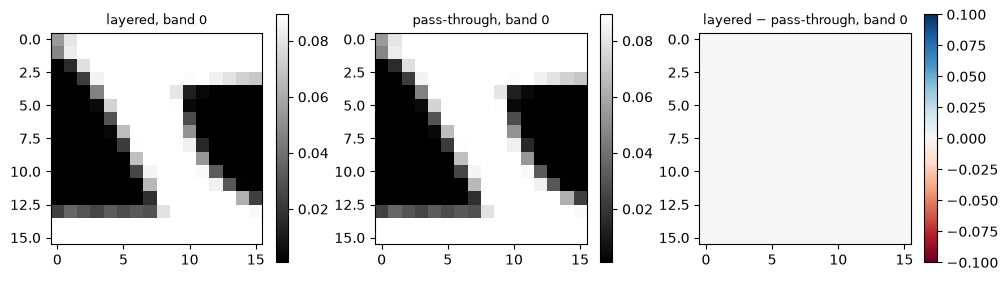

In [11]:
if metrics:
    n = next(iter(metrics))
    a, b = read_envi(pairs["layered"][n]), read_envi(pairs["pass-through"][n])
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
    for ax, im, title in zip(axes, (a[0], b[0], a[0] - b[0]), ("layered", "pass-through", "layered − pass-through")):
        h = ax.imshow(im, cmap="gray" if title != "layered − pass-through" else "RdBu")
        ax.set_title(f"{title}, band 0", fontsize=9)
        fig.colorbar(h, ax=ax, shrink=0.8)
    plt.tight_layout()
    plt.show()
else:
    print("SKIPPED: no layered comparison to plot")

---
# What this shows, and what the SDK does not expose

The recipe composed to one run spec whose run id is fixed before anything runs; the engine-free checks and the DIRSIG dry run passed; a uniform atmosphere with no weather values was refused before submission by the resolution check, with DIRSIG's reason and the member named; the run rendered with verdict `complete`, its artifacts carry roles and digests; a second work root gave the same id and the same product bytes; and the MaterialMap1 demo derived into the layered form rendered the same 16 × 16 image as the demo run as authored at the same seed.

Values a cell needed that the SDK does not expose, so the notebook took them elsewhere and says so:

- **Pixels.** `get_artifact` returns bytes and a media type; reading an ENVI image takes a reader outside the SDK (`scripts/compare_outputs.py`).
- **A demo's own values.** The layered form of a DIRSIG demo is derived from the demo's files by `scripts/compare_layered.py` (not an SDK surface; its values are licensed and never committed), and that script finds the installation's demo archive through the DIRSIG engine package, not through the `Workspace`.
- **The window of an as-authored platform.** A 16 × 16 demo render needs the demo's `.platform` edited before it is hashed; with `as_authored` there is no run-spec member for the window.
- **The installation.** `list_engines` says whether DIRSIG is available and gives the adapter's version, not where the installation is or which DIRSIG version it is; the setup cell reads `DIRSIG_HOME` for the demo archive.